In [3]:
import gymnasium as gym
from gymnasium import spaces
import numpy as np
import itertools
import time
import torch
import pylab as plt
# %matplotlib inline
# %matplotlib notebook
from mpl_toolkits.mplot3d import Axes3D
from matplotlib import cm

import memory as mem   
from feedforward import Feedforward

## Helper Functions

In [4]:
def running_mean(x, N):
    cumsum = np.cumsum(np.insert(x, 0, 0)) 
    return (cumsum[N:] - cumsum[:-N]) / float(N)

In [5]:
class DiscreteActionWrapper(gym.ActionWrapper):
    def __init__(self, env: gym.Env, bins = 5):
        """A wrapper for converting a 1D continuous actions into discrete ones.
        Args:
            env: The environment to apply the wrapper
            bins: number of discrete actions
        """
        assert isinstance(env.action_space, spaces.Box)
        super().__init__(env)
        self.bins = bins
        self.orig_action_space = env.action_space
        self.action_space = spaces.Discrete(self.bins)

    def action(self, action):
        """ discrete actions from low to high in 'bins'
        Args:
            action: The discrete action
        Returns:
            continuous action
        """
        return self.orig_action_space.low + action/(self.bins-1.0)*(self.orig_action_space.high-self.orig_action_space.low)  

# DQN

Complete the implemenation of DQN with a main Q-network and a target Q-network

In [ ]:
""" Q Network, input: observations, output: q-values for all actions """
class QFunction(Feedforward):
    def __init__(self, observation_dim, action_dim, 
                 hidden_sizes=[100,100], learning_rate = 0.0002):
        super().__init__(input_size=observation_dim, 
                         hidden_sizes=hidden_sizes, 
                         output_size=action_dim)
        self.optimizer=torch.optim.Adam(self.parameters(), 
                                        lr=learning_rate, 
                                        eps=0.000001)
        # The L1 loss is often easier for choosing learning rates etc than for L2 (MSELoss)
        #  Imagine larger q-values (in the hundreds) then an squared error can quickly be 10000!, 
        #  whereas the L1 (absolute) error is simply in the order of 100. 
        self.loss = torch.nn.SmoothL1Loss()
        
    def fit(self, observations, actions, targets):
        self.train() # put model in training mode
        self.optimizer.zero_grad()
        pred = self.Q_value(observations, actions)
        loss = self.loss(pred, torch.from_numpy(targets).float().view(-1, 1))
        loss.backward()
        self.optimizer.step()
        return loss.item()
    
    def Q_value(self, observations, actions):
        # compute the Q value for the give actions
        # Hint: use the torch.gather function select the right outputs 
        if not isinstance(observations, torch.Tensor):
            observations = torch.from_numpy(observations).float()
        if not isinstance(actions, torch.Tensor):
            actions = torch.from_numpy(actions).long()
        if actions.ndim == 1:
            actions = actions.unsqueeze(1)
        return self.forward(observations).gather(1, actions)
    
    def maxQ(self, observations):
        return np.max(self.predict(observations), axis=-1, keepdims=True)
    
    def greedyAction(self, observations):
        return np.argmax(self.predict(observations), axis=-1)

In [ ]:
class DQNAgent(object):
    """
    Agent implementing Q-learning with NN function approximation.    
    """
    def __init__(self, observation_space, action_space, **userconfig):    
        self._observation_space = observation_space
        self._action_space = action_space
        self._action_n = action_space.n
        self._config = {
            "eps": 0.05,            # Epsilon in epsilon greedy policies                        
            "discount": 0.95,
            "buffer_size": int(1e5),
            "batch_size": 128,
            "learning_rate": 0.0002, 
            "use_target_net": True,
            "update_target_every": 20,
        }
        self._config.update(userconfig)        
        self._eps = self._config['eps']
        self.buffer = mem.Memory(max_size=self._config["buffer_size"])
        
        # Q Network and Target Q Network
        self.Q = QFunction(observation_dim=self._observation_space.shape[0],
                           action_dim=self._action_n,
                           learning_rate=self._config["learning_rate"])
        self.Q_target = QFunction(observation_dim=self._observation_space.shape[0],
                                  action_dim=self._action_n,
                                  learning_rate=self._config["learning_rate"])
        self._update_target_net()
        self.train_iter = 0
            
    def _update_target_net(self):        
        # Hint: use load_state_dict() and state_dict() functions
        self.Q_target.load_state_dict(self.Q.state_dict())
    
    def act(self, observation, eps=None):
        if eps is None:
            eps = self._eps
        # epsilon greedy
        if np.random.random() > eps:
            action = self.Q.greedyAction(observation)
        else: 
            action = self._action_space.sample()        
        return action
    
    def store_transition(self, transition):
        self.buffer.add_transition(transition)
            
    def train(self, iter_fit=32):
        losses = []
        if self._config["use_target_net"] and (self.train_iter % self._config["update_target_every"] == 0):
            self._update_target_net()
        self.train_iter += 1
        
        for i in range(iter_fit):
            # sample from the replay buffer
            data = self.buffer.sample(batch=self._config["batch_size"])
            s = np.stack(data[:, 0]).astype(np.float32) # s_t
            a = np.stack(data[:, 1]).astype(np.int64)[:, None] # a_t
            rew = np.stack(data[:, 2]).astype(np.float32)[:, None] # r_{t+1}
            sp = np.stack(data[:, 3]).astype(np.float32) # s_{t+1}
            done = np.stack(data[:, 4]).astype(np.float32)[:, None] # d_{t+1}
            
            if self._config["use_target_net"]:
                v_prime = self.Q_target.maxQ(sp)
            else:
                v_prime = self.Q.maxQ(sp)
            
            td_target = rew + self._config["discount"] * (1.0 - done) * v_prime
            
            # optimize the Q objective
            fit_loss = self.Q.fit(s, a, td_target)
            losses.append(fit_loss)    
        return losses

## Test in Env

In [8]:
env_name = 'Pendulum-v1'
# env_name = 'CartPole-v1'

env = gym.make(env_name)
if isinstance(env.action_space, spaces.Box):
    env = DiscreteActionWrapper(env,5)

ac_space = env.action_space
o_space = env.observation_space
print(ac_space)
print(o_space)
print(list(zip(env.observation_space.low, env.observation_space.high)))

Discrete(5)
Box([-1. -1. -8.], [1. 1. 8.], (3,), float32)
[(np.float32(-1.0), np.float32(1.0)), (np.float32(-1.0), np.float32(1.0)), (np.float32(-8.0), np.float32(8.0))]


In [9]:
q_agent = DQNAgent(o_space, ac_space, discount=0.95, eps=0.2)

In [10]:
ob,_info = env.reset()
q_agent.Q.predict(ob)

array([ 0.08375411, -0.04135854,  0.14366183,  0.33495736, -0.14343572],
      dtype=float32)

Train the agent!

In [11]:
stats = []
losses = []

In [12]:
max_episodes=600
max_steps=500 
for i in range(max_episodes):
    # print("Starting a new episode")    
    total_reward = 0
    ob, _info = env.reset()
    for t in range(max_steps):
        done = False        
        a = q_agent.act(ob)
        (ob_new, reward, done, trunc, _info) = env.step(a)
        total_reward+= reward
        q_agent.store_transition((ob, a, reward, ob_new, done))            
        ob=ob_new        
        if done or trunc: break    
    losses.extend(q_agent.train(32))
    stats.append([i,total_reward,t+1])    
    
    if ((i-1)%20==0):
        print("{}: Done after {} steps. Reward: {}".format(i, t+1, total_reward))

1: Done after 200 steps. Reward: -1748.5568337188995
21: Done after 200 steps. Reward: -1722.6490729827985
41: Done after 200 steps. Reward: -1578.242186822068
61: Done after 200 steps. Reward: -1277.035746334266
81: Done after 200 steps. Reward: -1107.5596364599241
101: Done after 200 steps. Reward: -1750.8682002135183
121: Done after 200 steps. Reward: -380.986311280541
141: Done after 200 steps. Reward: -970.2125642484328
161: Done after 200 steps. Reward: -1078.5843596293441
181: Done after 200 steps. Reward: -131.40226749694148
201: Done after 200 steps. Reward: -1255.0661106441794
221: Done after 200 steps. Reward: -130.6749570908199
241: Done after 200 steps. Reward: -383.3271330768679
261: Done after 200 steps. Reward: -952.1076233620792
281: Done after 200 steps. Reward: -394.3386691555343
301: Done after 200 steps. Reward: -2.1497540969939544
321: Done after 200 steps. Reward: -621.7678253379424
341: Done after 200 steps. Reward: -259.3004846296557
361: Done after 200 steps. 

Plot the training reward over time. Use the running_mean(array, window_size) to plot a smooth version 

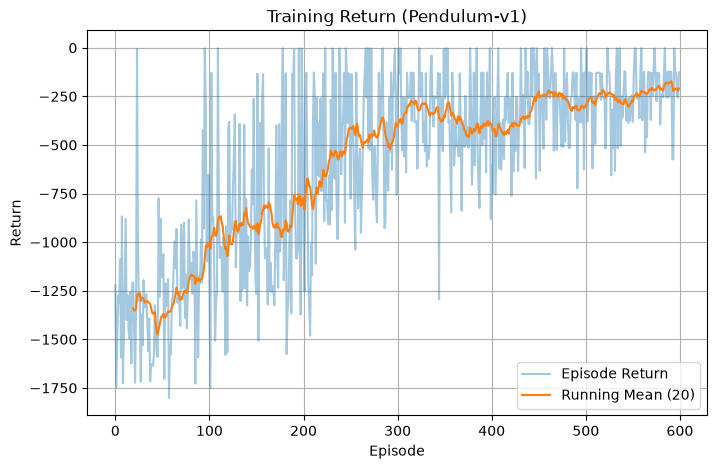

In [13]:
stats_np = np.asarray(stats)
fig = plt.figure(figsize=(8, 5))
plt.plot(stats_np[:, 0], stats_np[:, 1], alpha=0.4, label='Episode Return')
window = 20
rm = running_mean(stats_np[:, 1], window)
plt.plot(stats_np[window-1:, 0], rm, label=f'Running Mean ({window})')
plt.xlabel('Episode')
plt.ylabel('Return')
plt.title(f'Training Return ({env_name})')
plt.legend()
plt.grid(True)
plt.show()

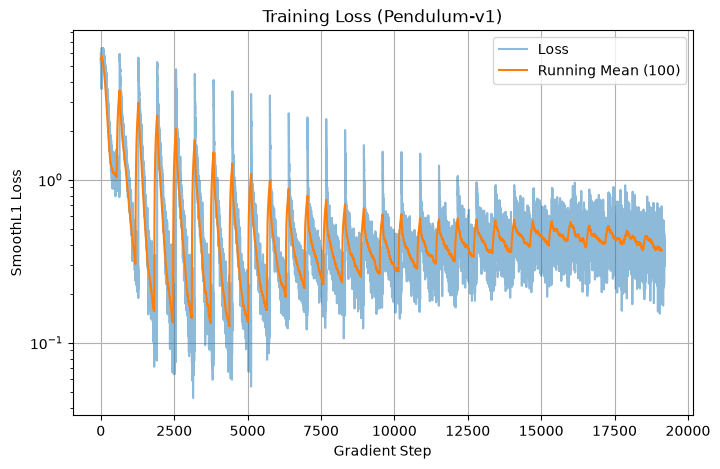

In [14]:
losses_np = np.asarray(losses)
fig_loss = plt.figure(figsize=(8, 5))
plt.plot(losses_np, alpha=0.5, label='Loss')
if len(losses_np) >= 100:
    plt.plot(running_mean(losses_np, 100), label='Running Mean (100)')
plt.yscale('log')
plt.xlabel('Gradient Step')
plt.ylabel('SmoothL1 Loss')
plt.title(f'Training Loss ({env_name})')
plt.legend()
plt.grid(True)
plt.show()

In [15]:
q_agent.buffer.size

100000

## Evaluate (without exploration)

Please look at the behavior for a small number of episodes

In [16]:
env_eval = gym.make(env_name, render_mode="human")
if isinstance(env_eval.action_space, spaces.Box):
    env_eval = DiscreteActionWrapper(env_eval,5)

In [17]:
test_stats = []
episodes=50
env_ = env    # without rendering
#env_ = env_eval # with rendering

for i in range(episodes):
    total_reward = 0
    ob, _info = env_.reset()
    for t in range(max_steps):
        done = False        
        a = q_agent.act(ob, eps=0.0)
        (ob_new, reward, done, trunc, _info) = env_.step(a)
        total_reward+= reward
        ob=ob_new        
        if done or trunc: break    
    test_stats.append([i,total_reward,t+1])        

Evaluate mean and standard deviation of performance 

(for the Pendulum: an average return around -30 or better should be achieved)

(for the CartPendulum it is possible to get 200)

In [18]:
test_stats_np = np.asarray(test_stats)
print("Test Return ({}): mean = {:.2f}, std = {:.2f}".format(
    env_name, np.mean(test_stats_np[:, 1]), np.std(test_stats_np[:, 1])))
print("Episode Length ({}): mean = {:.2f}, std = {:.2f}".format(
    env_name, np.mean(test_stats_np[:, 2]), np.std(test_stats_np[:, 2])))

Test Return (Pendulum-v1): mean = -134.15, std = 92.93
Episode Length (Pendulum-v1): mean = 200.00, std = 0.00


# Visualize

Visualization of the value function.

In [20]:
def plot_Q_function(q_function):
    plt.rcParams.update({'font.size': 12})
    xxs = np.linspace(-np.pi, np.pi, 50)
    yys = np.linspace(-8, 8, 50)
    XX, YY = np.meshgrid(xxs, yys)
    dots = np.asarray([np.cos(XX.ravel()), np.sin(XX.ravel()), YY.ravel()]).T
    values = q_function.maxQ(dots).reshape(XX.shape)

    fig = plt.figure(figsize=[10, 8])
    ax = fig.add_subplot(projection='3d')
    surf = ax.plot_surface(XX, YY, values, cmap=cm.coolwarm,
                           linewidth=0, antialiased=False)
    ax.view_init(elev=20, azim=45)
    ax.set_xlabel('angle')
    ax.set_ylabel('angle velocity')
    ax.set_zlabel('max Q')
    fig.colorbar(surf, shrink=0.5, aspect=10)
    plt.show()
    return fig

def plot_Q_function_generic(q_function, input_dims, plot_dim1=0, plot_dim2=1,
                            label_dim1='dim1', label_dim2='dim2',
                            range_dim1=(-1.0, 1.0), range_dim2=(-1.0, 1.0)):
    plt.rcParams.update({'font.size': 12})
    xxs = np.linspace(range_dim1[0], range_dim1[1], 50)
    yys = np.linspace(range_dim2[0], range_dim2[1], 50)
    XX, YY = np.meshgrid(xxs, yys)
    dots = np.zeros((XX.size, input_dims), dtype=np.float32)
    dots[:, plot_dim1] = XX.ravel()
    dots[:, plot_dim2] = YY.ravel()
    values = q_function.maxQ(dots).reshape(XX.shape)

    fig = plt.figure(figsize=[10, 8])
    ax = fig.add_subplot(projection='3d')
    surf = ax.plot_surface(XX, YY, values, cmap=cm.coolwarm,
                           linewidth=0, antialiased=False)
    ax.view_init(elev=20, azim=45)
    ax.set_xlabel(label_dim1)
    ax.set_ylabel(label_dim2)
    ax.set_zlabel('max Q')
    fig.colorbar(surf, shrink=0.5, aspect=10)
    plt.show()
    return fig

## Pendulum Env

Observation space:

0 angle

1 angular velocity

Do that for the pendulum function. Does it look like you expect?

Do that for the pendulum function. Does it look like you expect

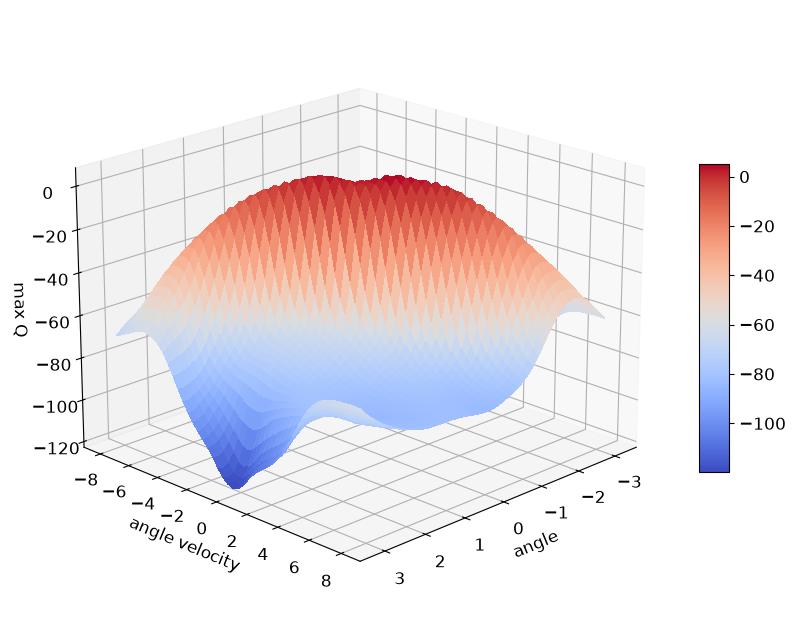

In [21]:
figQ = plot_Q_function(q_agent.Q)

## Task (c): Target Network Analysis (Pendulum-v1)

Compare training curves and final test performance after 600 episodes:
- without target network
- with target network updated every batch-training call (`update_target_every=1`)
- with target network updated every 20 batch-training calls (`update_target_every=20`)

[Pendulum-v1] No target net: Test Return = -162.62 +/- 75.63
[Pendulum-v1] Target net (every 1): Test Return = -141.36 +/- 101.45
[Pendulum-v1] Target net (every 20): Test Return = -174.99 +/- 101.25


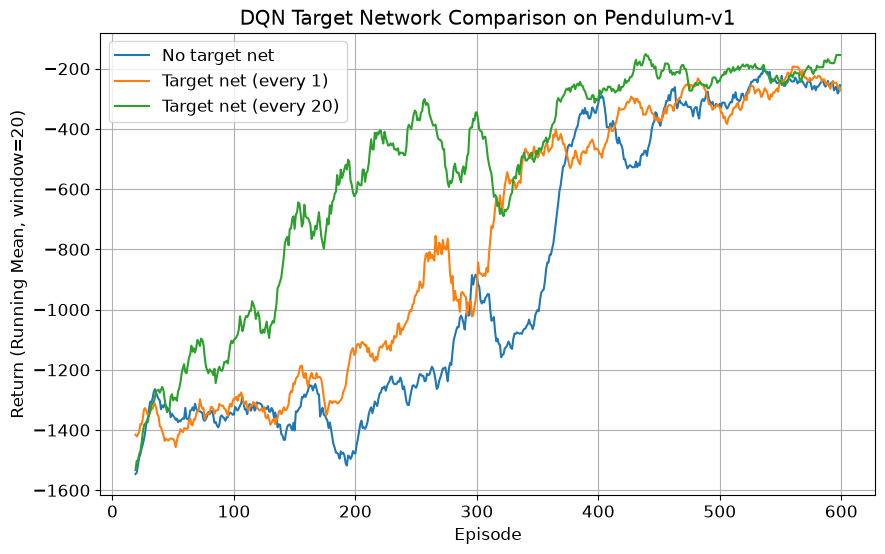

In [22]:
def run_dqn_comparison(env_name, max_episodes=600, max_steps=500, eval_episodes=50,
                       discount=0.95, eps=0.2, iter_fit=32, bins=5):
    configs = [
        ("No target net", {"use_target_net": False}),
        ("Target net (every 1)", {"use_target_net": True, "update_target_every": 1}),
        ("Target net (every 20)", {"use_target_net": True, "update_target_every": 20}),
    ]
    results = {}
    
    for label, cfg in configs:
        env_run = gym.make(env_name)
        if isinstance(env_run.action_space, spaces.Box):
            env_run = DiscreteActionWrapper(env_run, bins)
        
        agent = DQNAgent(env_run.observation_space, env_run.action_space,
                         discount=discount, eps=eps, **cfg)
        ep_rewards = []
        for i in range(max_episodes):
            total_reward = 0
            ob, _info = env_run.reset()
            for t in range(max_steps):
                a = agent.act(ob)
                ob_new, reward, done, trunc, _info = env_run.step(a)
                total_reward += reward
                agent.store_transition((ob, a, reward, ob_new, done))
                ob = ob_new
                if done or trunc:
                    break
            agent.train(iter_fit)
            ep_rewards.append(total_reward)
        
        # Evaluate without exploration
        eval_rewards = []
        for i in range(eval_episodes):
            total_reward = 0
            ob, _info = env_run.reset()
            for t in range(max_steps):
                a = agent.act(ob, eps=0.0)
                ob_new, reward, done, trunc, _info = env_run.step(a)
                total_reward += reward
                ob = ob_new
                if done or trunc:
                    break
            eval_rewards.append(total_reward)
        
        env_run.close()
        mean_eval = np.mean(eval_rewards)
        std_eval = np.std(eval_rewards)
        print(f"[{env_name}] {label}: Test Return = {mean_eval:.2f} +/- {std_eval:.2f}")
        results[label] = {
            "train_rewards": np.asarray(ep_rewards),
            "eval_rewards": np.asarray(eval_rewards),
            "agent": agent,
            "o_space": env_run.observation_space,
        }
    
    # Plot comparison of training curves
    window = 20
    plt.figure(figsize=(10, 6))
    for label, res in results.items():
        rm = running_mean(res["train_rewards"], window)
        plt.plot(np.arange(window - 1, len(res["train_rewards"])), rm, label=label)
    plt.xlabel("Episode")
    plt.ylabel(f"Return (Running Mean, window={window})")
    plt.title(f"DQN Target Network Comparison on {env_name}")
    plt.legend()
    plt.grid(True)
    plt.show()
    return results

pendulum_results = run_dqn_comparison('Pendulum-v1', max_episodes=600, max_steps=500, eval_episodes=50)

## Cartpole Env

[CartPole-v1] No target net: Test Return = 102.88 +/- 3.78
[CartPole-v1] Target net (every 1): Test Return = 192.24 +/- 19.29
[CartPole-v1] Target net (every 20): Test Return = 130.64 +/- 8.80


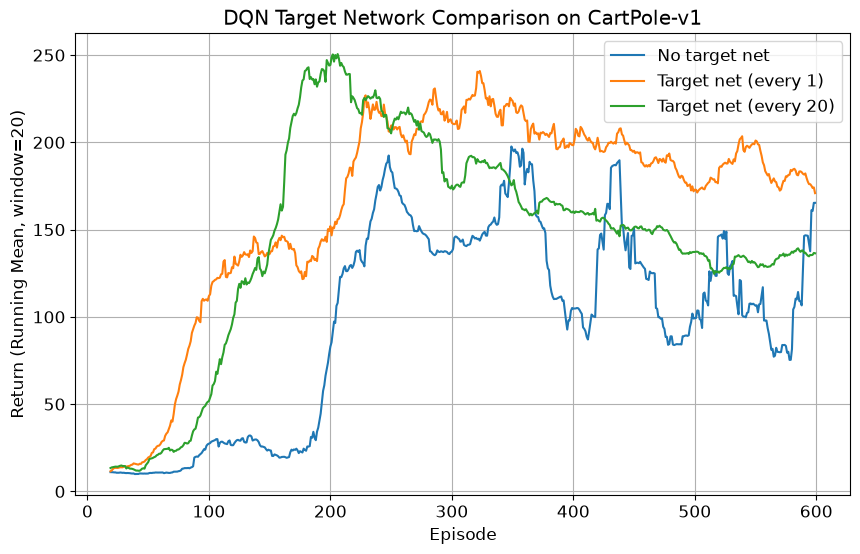

In [23]:
# Task (e): Run the same procedure for CartPole-v1
cartpole_results = run_dqn_comparison('CartPole-v1', max_episodes=600, max_steps=500, eval_episodes=50)

# Use the trained agent (target net updated every 20 calls) for value function visualization below
q_agent = cartpole_results["Target net (every 20)"]["agent"]
o_space = cartpole_results["Target net (every 20)"]["o_space"]

Observation space:
 
0       Cart Position             -4.8                    4.8

1       Cart Velocity             -Inf                    Inf

2       Pole Angle                -0.418 rad (-24 deg)    0.418 rad (24 deg)

3       Pole Angular Velocity     -Inf                    Inf

Try to adapt the plotting function that it also works in higher input spaces where all other inputs are 0

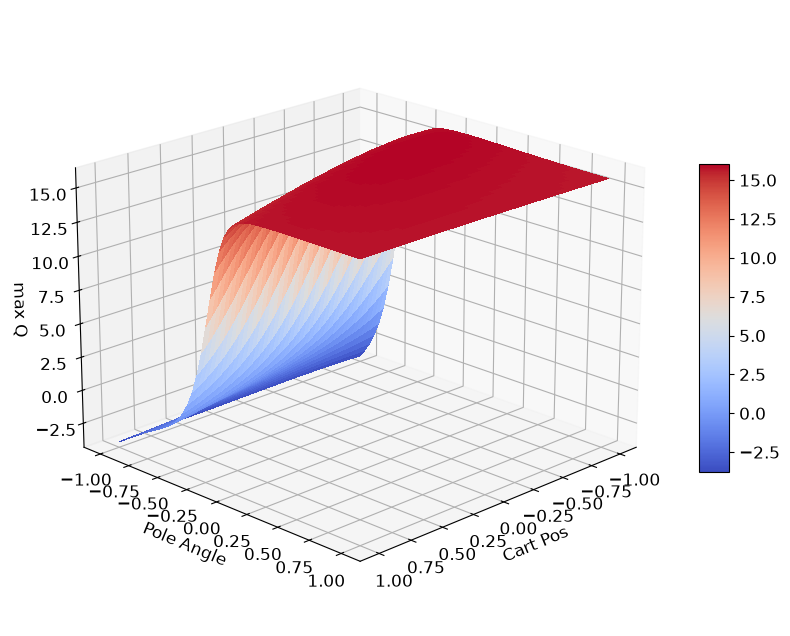

In [24]:
figQ = plot_Q_function_generic(q_agent.Q, input_dims=o_space.shape[0], plot_dim1=0, plot_dim2=2, 
                       label_dim1="Cart Pos", label_dim2="Pole Angle")

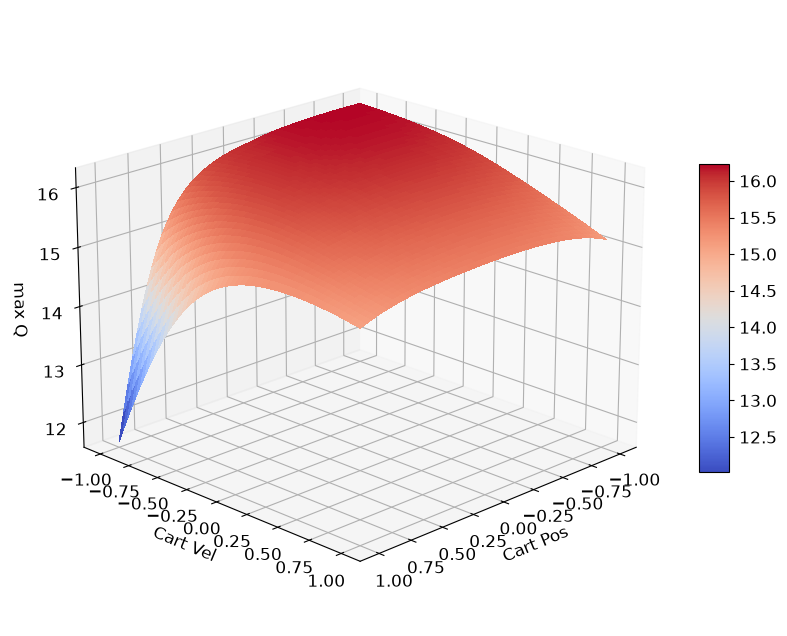

In [25]:
figQ = plot_Q_function_generic(q_agent.Q, input_dims=o_space.shape[0], plot_dim1=0, plot_dim2=1, 
                       label_dim1="Cart Pos", label_dim2="Cart Vel")

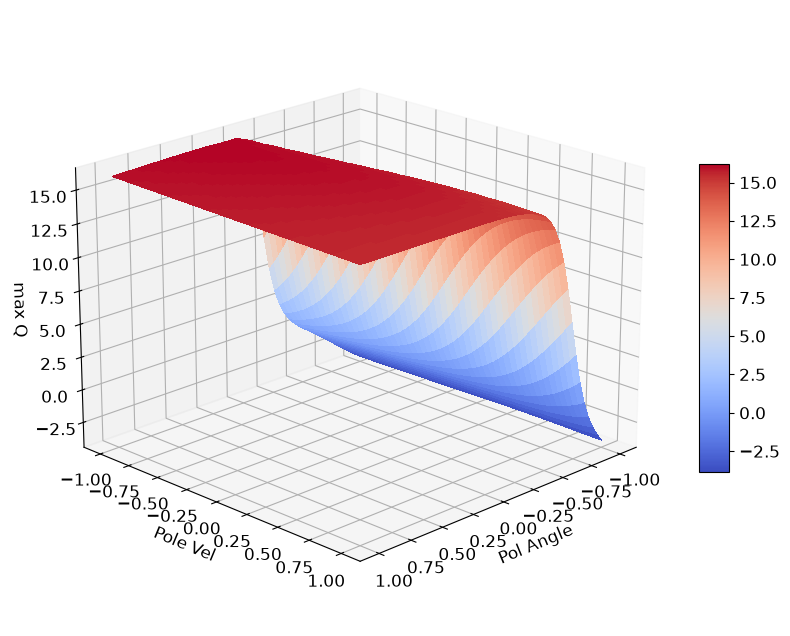

In [26]:
figQ = plot_Q_function_generic(q_agent.Q, input_dims=o_space.shape[0], plot_dim1=2, plot_dim2=3, 
                       label_dim1="Pol Angle", label_dim2="Pole Vel")

In [27]:
%matplotlib notebook

In [ ]:
# env_name = 'Acrobot-v1'
# env_name = 'MountainCar-v0'
# env_name = 'LunarLander-v2'